Import Libraries

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [56]:
df = pd.read_csv('data/raw/WA_Fn-UseC_-HR-Employee-Attrition.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [57]:
print("Dataset shape:", df.shape)    #dimensions

Dataset shape: (1470, 35)


In [58]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [59]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [60]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [61]:
df['Attrition'].value_counts()     # attrition distribution

Attrition
No     1233
Yes     237
Name: count, dtype: int64

This means most employees stayed with the company, while 237 employees left.

In [62]:
attrition_percentage = df['Attrition'].value_counts(normalize=True) * 100

print(attrition_percentage)         # calculating attrition percentage

Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


**HR interpretation:**  Approximately 16 out of every 100 employees in this dataset left the organization. This gives HR a baseline for investigating possible attrition factors.

Create our first visualization

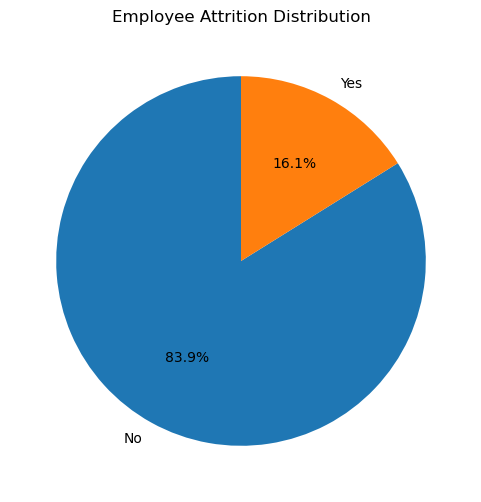

In [63]:
attrition_counts = df['Attrition'].value_counts()

plt.figure(figsize=(6, 6))

plt.pie(
    attrition_counts,
    labels=attrition_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Employee Attrition Distribution')
plt.show()

In [64]:
department_attrition = df.groupby('Department')['Attrition'].value_counts()

print(department_attrition)      # deaprtment wise attrition

Department              Attrition
Human Resources         No            51
                        Yes           12
Research & Development  No           828
                        Yes          133
Sales                   No           354
                        Yes           92
Name: count, dtype: int64


**Initial observation:** Research & Development has the highest number of employees leaving (133), followed by Sales (92).

R&D also has the largest workforce. So we shouldn't conclude it has the highest attrition risk based only on counts.

In [65]:
department_rate = df.groupby('Department')['Attrition'].apply(
    lambda x: (x == 'Yes').mean() * 100
)

print(department_rate)                      # Calculating dept wise attrition rate

Department
Human Resources           19.047619
Research & Development    13.839750
Sales                     20.627803
Name: Attrition, dtype: float64


**Sales has the highest attrition rate (20.63%)**, even though Research & Development has the highest number of employees leaving.

This is exactly why HR Analytics uses percentages rather than relying only on employee counts.

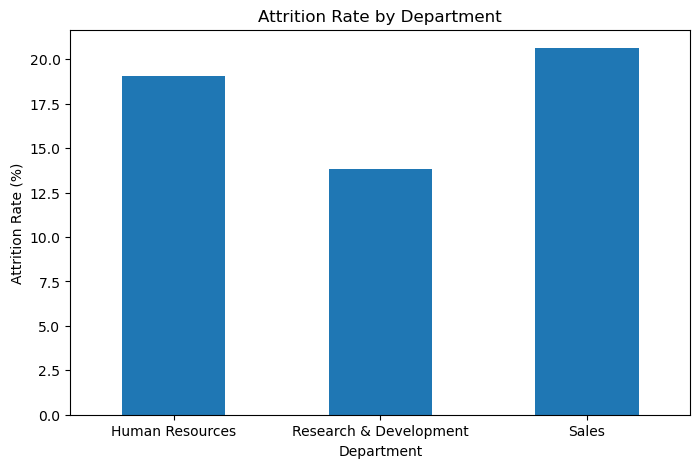

In [66]:
plt.figure(figsize=(8, 5))     # visualizing dept-wise atrrition

department_rate.plot(kind='bar')

plt.title('Attrition Rate by Department')
plt.xlabel('Department')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.show()

**Business insight:**
The Sales department may need closer attention from HR. Further investigation into workload, overtime, compensation and job satisfaction could help identify possible reasons behind its higher attrition rate.

Analyze attrition by Overtime

In [67]:
overtime_attrition = df.groupby('OverTime')['Attrition'].apply(
    lambda x: (x == 'Yes').mean() * 100
)

print(overtime_attrition)

OverTime
No     10.436433
Yes    30.528846
Name: Attrition, dtype: float64


Employees who work overtime have a substantially higher attrition rate than employees who don't.

The difference is approximately 20.09 percentage points.


**Business Interpretation**
This suggests a possible relationship between overtime and employee attrition. HR should investigate workload, work-life balance and employee burnout.



This is an association, not proof that overtime causes employees to leave.

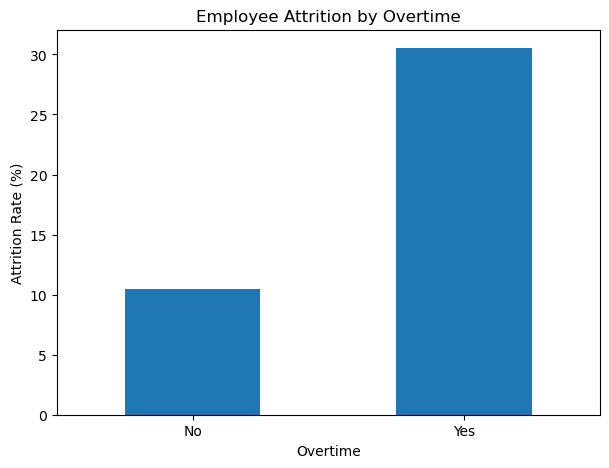

In [68]:
plt.figure(figsize=(7, 5))       # Visualize Overtim Attrition

overtime_attrition.plot(kind='bar')

plt.title('Employee Attrition by Overtime')
plt.xlabel('Overtime')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.show()

**Our second important business insight:** employees working overtime show nearly 3 times the attrition rate of those who don't.

Analyze Monthly income and attrition

In [69]:
income_analysis = df.groupby('Attrition')['MonthlyIncome'].mean()

print(income_analysis)

Attrition
No     6832.739659
Yes    4787.092827
Name: MonthlyIncome, dtype: float64


**Interpretation:** Employees who left had a lower average monthly income than employees who stayed.

This suggests that compensation may be associated with employee retention. However, salary alone doesn't explain why employees leave.

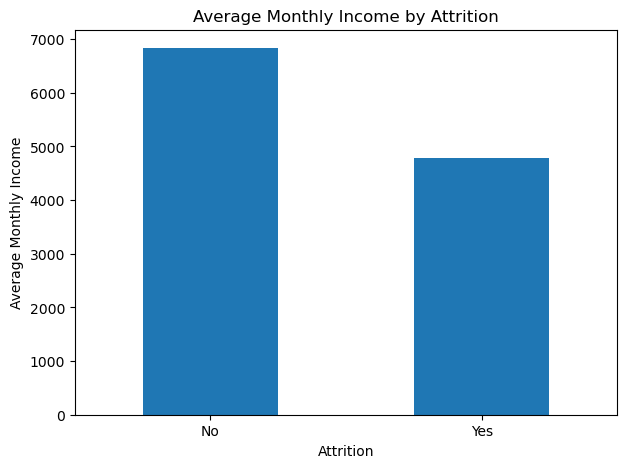

In [70]:
plt.figure(figsize=(7, 5))       # visualize average income

income_analysis.plot(kind='bar')

plt.title('Average Monthly Income by Attrition')
plt.xlabel('Attrition')
plt.ylabel('Average Monthly Income')
plt.xticks(rotation=0)
plt.show()

In [71]:
satisfaction_analysis = df.groupby('Attrition')['JobSatisfaction'].mean()

print(satisfaction_analysis)    #analyze job satisfaction

Attrition
No     2.778589
Yes    2.468354
Name: JobSatisfaction, dtype: float64


**Interpretation:** Employees who stayed had a higher average job satisfaction score than employees who left.

This suggests job satisfaction may be associated with employee retention.

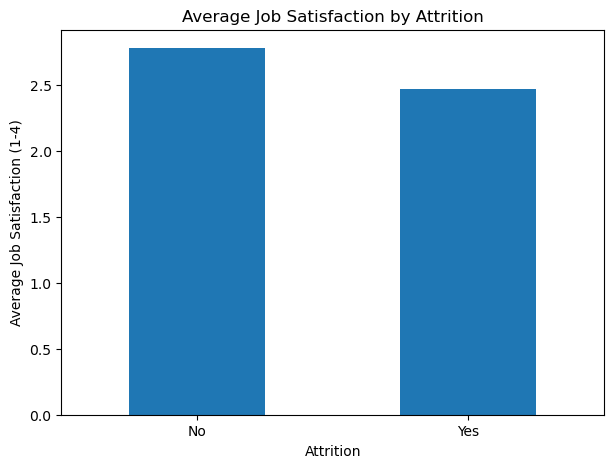

In [72]:
plt.figure(figsize=(7, 5))       # visualize job satisfaction

satisfaction_analysis.plot(kind='bar')

plt.title('Average Job Satisfaction by Attrition')
plt.xlabel('Attrition')
plt.ylabel('Average Job Satisfaction (1-4)')
plt.xticks(rotation=0)
plt.show()

Employees who stayed reported higher average job satisfaction.

In [73]:
age_analysis = df.groupby('Attrition')['Age'].mean()
     
print(age_analysis)                 # analyze employee age

Attrition
No     37.561233
Yes    33.607595
Name: Age, dtype: float64


**Interpretation:** Employees who left the company were younger on average (approximately 34 years) than employees who stayed (approximately 38 years).

This suggests that younger employees may be more likely to leave in this dataset. However, age alone does not explain why employees leave.

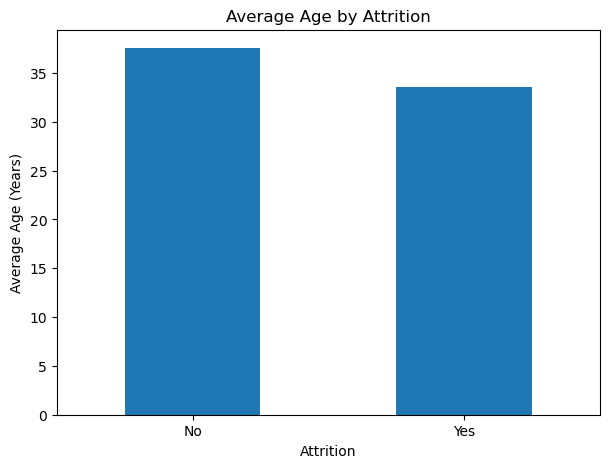

In [74]:
plt.figure(figsize=(7, 5))         # creating visualization

age_analysis.plot(kind='bar')

plt.title('Average Age by Attrition')
plt.xlabel('Attrition')
plt.ylabel('Average Age (Years)')
plt.xticks(rotation=0)

plt.show()

In [75]:
years_analysis = df.groupby('Attrition')['YearsAtCompany'].mean()
print(years_analysis)             # years at company by attrition

Attrition
No     7.369019
Yes    5.130802
Name: YearsAtCompany, dtype: float64


**Interpretation:** Employees who left had worked at the company for an average of approximately 5.13 years, compared with 7.37 years for employees who stayed.

This suggests that employees with shorter company tenure were more likely to leave in this dataset.

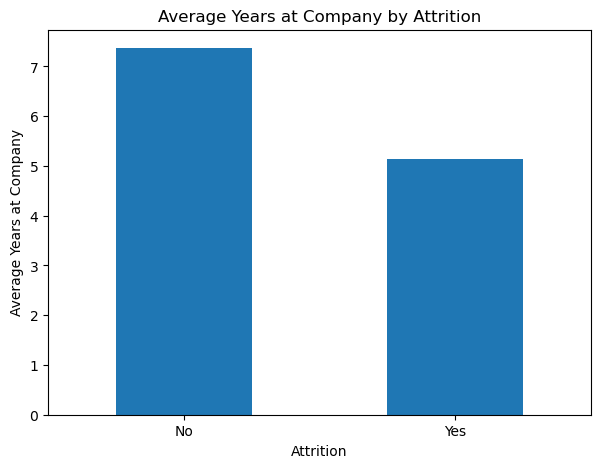

In [76]:
plt.figure(figsize=(7, 5))        # visualizing

years_analysis.plot(kind='bar')

plt.title('Average Years at Company by Attrition')
plt.xlabel('Attrition')
plt.ylabel('Average Years at Company')
plt.xticks(rotation=0)

plt.show()

Employees who stayed had longer average company tenure.

In [77]:
worklife_analysis = df.groupby('Attrition')['WorkLifeBalance'].mean()
print(worklife_analysis)                 # Work-life balance by attrition

Attrition
No     2.781022
Yes    2.658228
Name: WorkLifeBalance, dtype: float64


**Interpretation:** Employees who stayed had a slightly higher average Work-Life Balance score than employees who left.

The difference is small (0.12 points), so we should not overstate its importance.

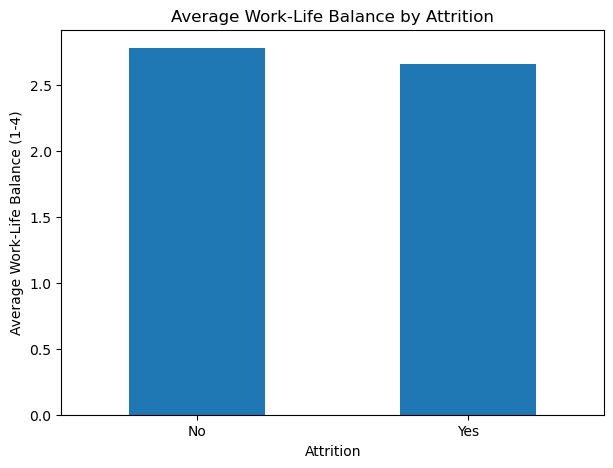

In [78]:
plt.figure(figsize=(7, 5))       # visualizing

worklife_analysis.plot(kind='bar')

plt.title('Average Work-Life Balance by Attrition')
plt.xlabel('Attrition')
plt.ylabel('Average Work-Life Balance (1-4)')
plt.xticks(rotation=0)

plt.show()

Attrition Rate by Job Role

In [79]:
jobrole_attrition = df.groupby('JobRole')['Attrition'].apply(
    lambda x: (x == 'Yes').mean() * 100
)

print(jobrole_attrition.sort_values(ascending=False))

JobRole
Sales Representative         39.759036
Laboratory Technician        23.938224
Human Resources              23.076923
Sales Executive              17.484663
Research Scientist           16.095890
Manufacturing Director        6.896552
Healthcare Representative     6.870229
Manager                       4.901961
Research Director             2.500000
Name: Attrition, dtype: float64


Key findings
1. Sales Representatives have the highest attrition rate (39.76%).
2. Laboratory Technicians are second (23.94%).
3. Research Directors have the lowest attrition rate (2.50%).
4. Sales-related roles show a noticeable retention concern, especially Sales Representatives.

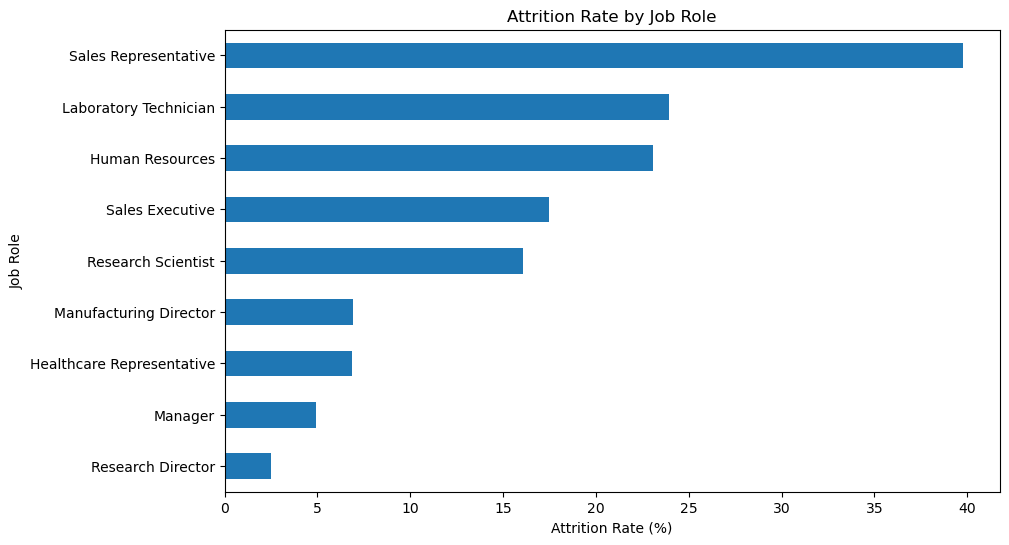

In [80]:
plt.figure(figsize=(10, 6))          # Visualize the results

jobrole_attrition.sort_values().plot(kind='barh')

plt.title('Attrition Rate by Job Role')
plt.xlabel('Attrition Rate (%)')
plt.ylabel('Job Role')

plt.show()

## Key Findings

1. Overall employee attrition is 16.12%.
2. Sales department has the highest attrition rate (20.63%).
3. Employees working overtime have a higher attrition rate (30.53%) than those not working overtime (10.44%).
4. Employees who left had a lower average monthly income (4787.09) than employees who stayed (6832.74).
5. Employees who stayed had higher average job satisfaction (2.78) than employees who left (2.47).
6. Employees who left were younger on average (33.61 years) than employees who stayed (37.56 years).
7. Employees who stayed had longer average company tenure (7.37 years) than employees who left (5.13 years).
8. Employees who stayed had slightly higher average work-life balance scores.
9. Sales Representatives had the highest job-role attrition rate (39.76%).

## Conclusion

The analysis identifies overtime, lower average income, shorter company tenure, and certain job roles as areas associated with higher employee attrition.

HR teams can investigate these patterns to develop better employee retention strategies.